            Agr  Min   Man   PS  Con    SI  Fin   SPS   TC
Belgium     3.3  0.9  27.6  0.9  8.2  19.1  6.2  26.6  7.2
Denmark     9.2  0.1  21.8  0.6  8.3  14.6  6.5  32.2  7.1
France     10.8  0.8  27.5  0.9  8.9  16.8  6.0  22.6  5.7
W.Germany   6.7  1.3  35.8  0.9  7.3  14.4  5.0  22.3  6.1
Ireland    23.2  1.0  20.7  1.3  7.5  16.8  2.8  20.8  6.1
Shape after PCA: (26, 2)


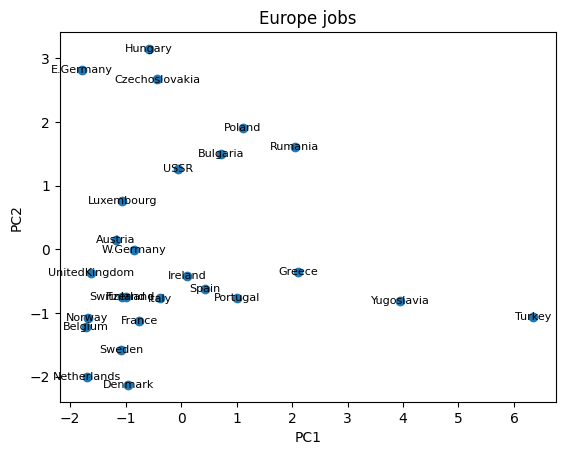

Explained variance ratio:
[0.387 0.237]
Cumulative variance explained:
[0.38746125 0.62414716]
PCA loadings (weights for each feature):


,PC1,PC2
Agr,0.523791,0.053594
Min,0.001323,0.617807
Man,-0.347495,0.355054
PS,-0.255716,0.261096
Con,-0.325179,0.051288
SI,-0.378920,-0.350172
Fin,-0.074374,-0.453698
SPS,-0.387409,-0.221521
TC,-0.366823,0.202592


Agr    0.523791
SPS    0.387409
SI     0.378920
TC     0.366823
Man    0.347495
Con    0.325179
PS     0.255716
Fin    0.074374
Min    0.001323
Name: PC1, dtype: float64
Min    0.617807
Fin    0.453698
Man    0.355054
SI     0.350172
PS     0.261096
SPS    0.221521
TC     0.202592
Agr    0.053594
Con    0.051288
Name: PC2, dtype: float64


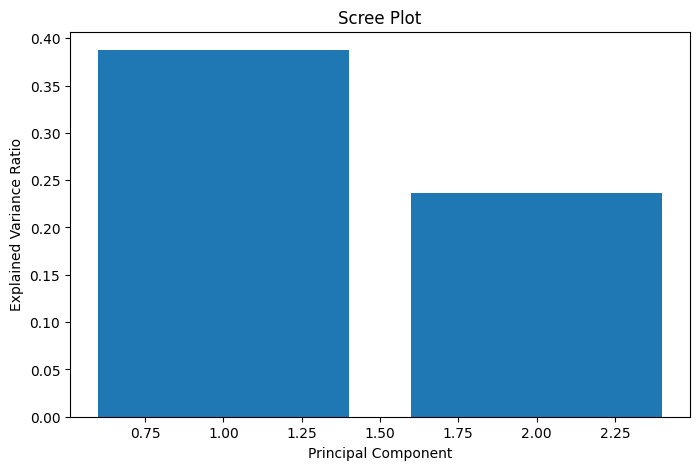

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path as PATH

path = PATH("data/europejobs.csv")
jobs = pd.read_csv(path)    
print(jobs.head())

jobs_scaled = StandardScaler().fit_transform(jobs)
pca_2d = PCA(n_components=2)
pca = pca_2d.fit(jobs_scaled)
X_pca = pca.transform(jobs_scaled)


print("Shape after PCA:", X_pca.shape)

fig, ax = plt.subplots()
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1])
for i in range(len(jobs)):
    plt.text(X_pca[i, 0], X_pca[i, 1], jobs.index[i],
             fontsize=8, ha="center", va="center")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Europe jobs")
plt.show()

print("Explained variance ratio:")
print(np.round(pca.explained_variance_ratio_, 3))
print("Cumulative variance explained:")
print(np.cumsum(pca.explained_variance_ratio_))


loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=jobs.columns
)
print("PCA loadings (weights for each feature):")
display(loadings)
print(loadings["PC1"].abs().sort_values(ascending=False)) # print and display have similar function but display looks better
print(loadings["PC2"].abs().sort_values(ascending=False))

#scree plot
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(pca.explained_variance_ratio_)+1), pca.explained_variance_ratio_)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.show()

Task1: Understanding the principal components

Look at the PCA loadings for PC1 and PC2.

1. Which three variables have the largest absolute
    loadings on PC1?

2. Which variables have positive and which have
    negative loadings on PC1?

3. Based on these loadings, how would you interpret PC1?
    What does a country with a high PC1 score represent?

4. Find two countries that are far apart along PC1.

    How do their employment structures differ?

Task 2: Explained variance

1. How much of the total variance is explained by
    the first two principal components?

2. Fit PCA using all available components.

3. What is the explained variance ratio for each
    component?

4. How many components are needed to explain
    at least 80% of the total variance?

5. Would you consider two principal components
    sufficient for this dataset? Explain.